In [18]:
import numpy as np
import matplotlib.pyplot as plt
import socket
import struct
import scipy
from time import sleep
import time

RP_ADDRESS = "RP-F0A360.LOCAL"
PORT = 5000

In [39]:
def send_msg(msg, s):
    msg = struct.pack('>I', len(msg)) + msg

    print("Sending message!")
    s.sendall(msg)

    sleep(0.1)

    # msg = s.recv(1024)
    # print('Received: ' + msg.decode())

def send_msg_n_bytes(msg, s):
    msg = struct.pack('>I', len(msg)) + msg

    print("Sending message!")
    s.sendall(msg)

    msg = s.recv(5)
    N = int(msg.decode())

    print(N)
    print('Received: len = ' + msg.decode())

    return N

def transform_waveform(waveform):
    waveform *= 32767
    waveform = np.round(waveform)

    waveform = waveform.astype(np.int16)

    fig, ax = plt.subplots()

    ax.plot(waveform)

    plt.show()
    # print(waveform)
    waveform = waveform.astype('>i2').tobytes()

    return waveform

def transform_waveform_2(waveform, offset):
    waveform *= 32767
    waveform = np.round(waveform)

    waveform = waveform.astype(np.int16) + np.round(offset*32767).astype(np.int16)

    fig, ax = plt.subplots()

    ax.plot(waveform)

    plt.show()
    # print(waveform)
    waveform = waveform.astype('>i2').tobytes()

    return waveform

def recv_n_bytes(s, n):
    """
    Receives exactly n bytes from the socket.
    """
    chunks = []
    bytes_recd = 0
    while bytes_recd < n:
        chunk = s.recv(n - bytes_recd)
        if not chunk:
            raise socket.error("Socket connection broken")
        chunks.append(chunk)
        bytes_recd += len(chunk)
    return b''.join(chunks)


def recv_msg(s):
    """
    Receives a message with a 7-byte length header followed by the message body.
    Ensures exactly N bytes are received in the second part.
    """
    try:
        # Receive the 7-byte header
        header = recv_n_bytes(s, 10)  # Reliable read for 7 bytes
        # print(header)
        
        # Decode the header to get the length
        N = int(header.decode())
        print(f"Message length: {N}")
        
        # Receive the actual message (exactly N bytes)
        msg = recv_n_bytes(s, N)

        print(f"Received!")
        
        return msg
    except (ValueError, socket.error) as e:
        print(f"Error in recv_msg: {e}")
        return b''


In [20]:
tcp_socket = socket.create_connection((RP_ADDRESS, PORT))

In [111]:
# resx, resy = 300, 300
# frame_time = 333

# waveform_len_1 = int(2*resx)

# dec1 = int(125000000 * 0.95 * frame_time / 1000 / waveform_len_1)

# waveform_len_2 = int(2*resy)

# dec2 = int(dec1 * 1.9 / waveform_len_2)

# acq_dec = int(dec2 * 0.95)

# print(dec1, dec2, acq_dec)

# print("Speed: {:.2f} Mbit/s".format(125000000 / acq_dec * 64 / 1000000))

Sending message!


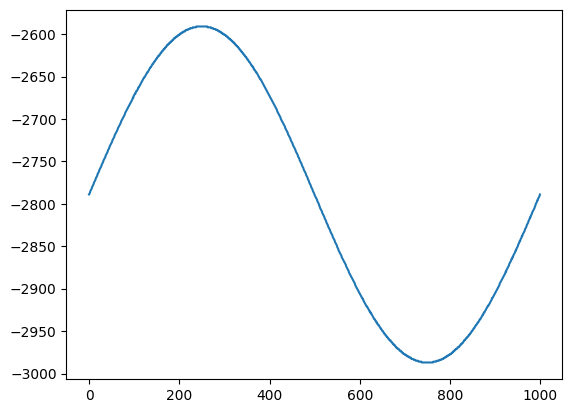

Sending message!
Sending message!
Sending message!


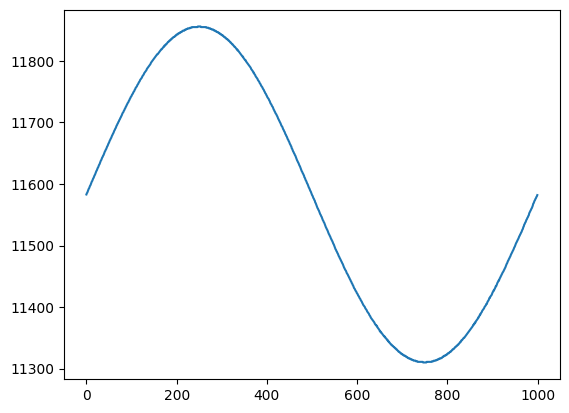

Sending message!
Sending message!


In [41]:
factor = 10.75

waveform_len_1 = 1000
dec1 = 125

waveform_len_2 = 1000
dec2 = int(125)

acq_dec = 120

msg = "set_waveform 0 {}".format(waveform_len_1)
msg = str.encode(msg)
send_msg(msg, tcp_socket)

x = np.linspace(0, 1, waveform_len_1, dtype=np.float16)
waveform = np.sin(2*np.pi*x) * 0.130/2 
waveform /= factor
# waveform = scipy.signal.sawtooth(2*np.pi*x, 0.975)*0.1
msg = transform_waveform_2(waveform, -0.915 / factor)
send_msg(msg, tcp_socket)

msg = "set_gen_decimation 0 {}".format(dec1)
msg = str.encode(msg)
send_msg(msg, tcp_socket)

msg = "set_waveform 1 {}".format(waveform_len_2)
msg = str.encode(msg)
send_msg(msg, tcp_socket)

x = np.linspace(0, 1, waveform_len_2, dtype=np.float16)
waveform = np.sin(2*np.pi*x) * 0.179/2
waveform /= factor
# waveform = scipy.signal.sawtooth(2*np.pi*x, 0.975)*0.1
# msg = transform_waveform(waveform)
msg = transform_waveform_2(waveform, 3.8 / factor)
send_msg(msg, tcp_socket)

msg = "set_gen_decimation 1 {}".format(dec2)
msg = str.encode(msg)
send_msg(msg, tcp_socket)

In [42]:
msg = "start_gen"
msg = str.encode(msg)
send_msg(msg, tcp_socket)

Sending message!


In [43]:
msg = "stop_gen"
msg = str.encode(msg)
send_msg(msg, tcp_socket)

Sending message!


In [115]:
# msg = "set_lim {} {} {} {}".format(-11000, 11000, -11000, 11000)
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

# msg = "set_res {} {}".format(resx, resy)
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

# msg = "set_frame_time {}".format(frame_time)
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

In [116]:
# msg = "set_waveform 0 {}".format(waveform_len_1)
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

# x = np.linspace(0, 1, waveform_len_1, dtype=np.float16)
# # waveform = np.sin(2*np.pi*x)*0.75
# waveform = scipy.signal.sawtooth(2*np.pi*x, 0.5)*0.3
# msg = transform_waveform(waveform)
# send_msg(msg, tcp_socket)

# msg = "set_gen_decimation 0 {}".format(dec1)
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

# msg = "set_waveform 1 {}".format(waveform_len_2)
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

# x = np.linspace(0, 1, waveform_len_2, dtype=np.float16)
# waveform = np.sin(2*np.pi*x)*0.3
# # waveform = scipy.signal.sawtooth(2*np.pi*x, 0.95)*0.5
# msg = transform_waveform(waveform)
# send_msg(msg, tcp_socket)

# msg = "set_gen_decimation 1 {}".format(dec2)
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

In [117]:
msg = "set_acq_decimation {}".format(acq_dec)
msg = str.encode(msg)
send_msg(msg, tcp_socket)

msg = "set_int_decimation 1"
msg = str.encode(msg)
send_msg(msg, tcp_socket)

Sending message!
Sending message!


In [118]:
# msg = "start_gen"
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

# msg = "start_acq"
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

# # sleep(2)
# arr = []
# start_time = time.time()  # Record the start time
# while time.time() - start_time < 10:  # Run while the elapsed time is less than n
#     print("krele")
#     arr += recv_msg(tcp_socket)

# msg = "stop_acq"
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

# msg = "stop_gen"
# msg = str.encode(msg)
# send_msg(msg, tcp_socket)

In [119]:
msg = "start_gen"
msg = str.encode(msg)
send_msg(msg, tcp_socket)

msg = "start_acq"
msg = str.encode(msg)
send_msg(msg, tcp_socket)

# sleep(2)
byte_arr = b""
start_time = time.time()  # Record the start time
while time.time() - start_time < 2:  # Run while the elapsed time is less than n
    byte_arr += tcp_socket.recv(int(1e6*8*2))

msg = "stop_acq"
msg = str.encode(msg)
send_msg(msg, tcp_socket)

msg = "stop_gen"
msg = str.encode(msg)
send_msg(msg, tcp_socket)

Sending message!
Sending message!
Sending message!
Sending message!


In [120]:
# byte_arr = bytes(arr[1000000:])

# images = []

# # Define the step size for the pattern [int16, int16, int32]
# step = 1

# # Iterate through the byte data
# for i in range(0, len(byte_arr), step):
#     # Ensure there are enough bytes left to unpack
#     if len(byte_arr[i:i + step]) < step:
#         print(f"Incomplete data block at index {i}, skipping.")
#         continue

#     # Unpack the current group of bytes
#     part = struct.unpack('>B', byte_arr[i:i + step])  # '<' for little-endian, 'hhI' for 2 int16 and 1 int32
#     images.append(part)

# images = np.array(images)

# images = images.reshape(-1, resx*resy)

# # for image in images:
# #     print(np.amax(image), np.amin(image))

In [121]:
# fig, ax = plt.subplots()

# ax.imshow(images[-1].reshape(resx, resy))

# plt.show()

In [122]:
# byte_arr = b''.join(byte_arr)

record_dtype = np.dtype([('x', np.int16), ('y', np.int16), ('value', np.uint32)])
record_size = record_dtype.itemsize

# Trim incomplete trailing bytes if necessary
if len(byte_arr) % record_size != 0:
    byte_arr = byte_arr[:-(len(byte_arr) % record_size)]

data = np.frombuffer(byte_arr, dtype=record_dtype)

x_array = data['x'].astype(np.float32)
y_array = data['y'].astype(np.float32)
value_array = data['value'].astype(np.float32)

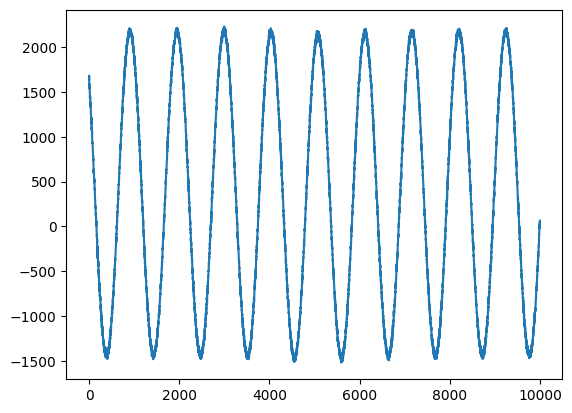

In [123]:
fig, ax = plt.subplots()

# ax.plot(data[-100000:, 0])
ax.plot(y_array[1:10000])

plt.show()

In [124]:
# msg = "exit"
# msg = str.encode(msg)
# try:
#     send_msg(msg, tcp_socket)
# except:
#     pass